# Random Forest

Accuracy (RF): 0.9580
ROC AUC (RF): 0.9950

Classification Report (RF):
              precision    recall  f1-score   support

           0       0.96      0.92      0.94        53
           1       0.96      0.98      0.97        90

    accuracy                           0.96       143
   macro avg       0.96      0.95      0.95       143
weighted avg       0.96      0.96      0.96       143

Confusion Matrix (RF):
[[49  4]
 [ 2 88]]
OOB Score: 0.9624


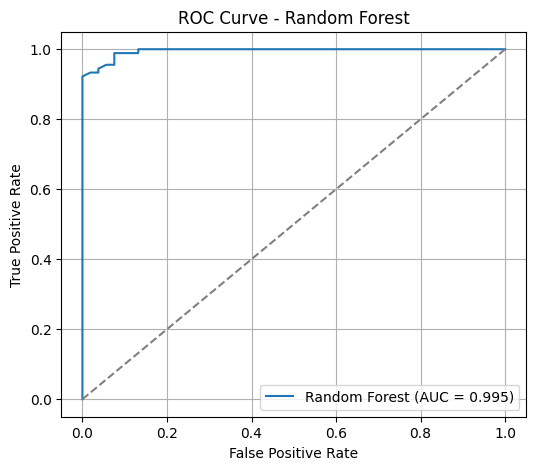

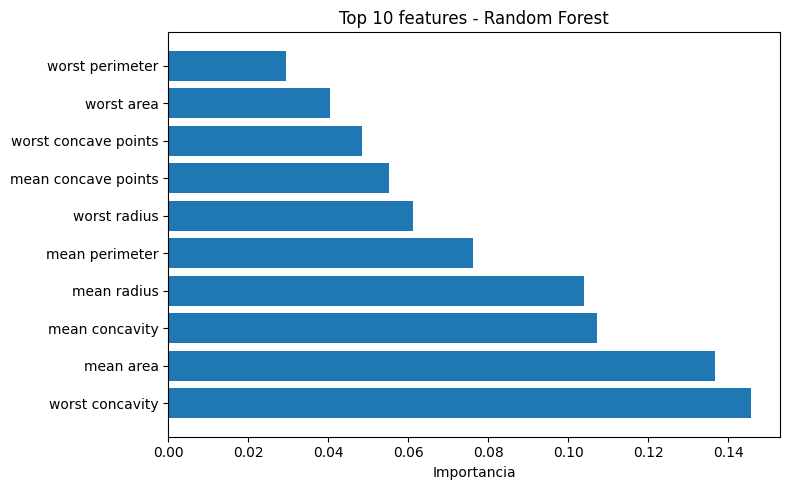

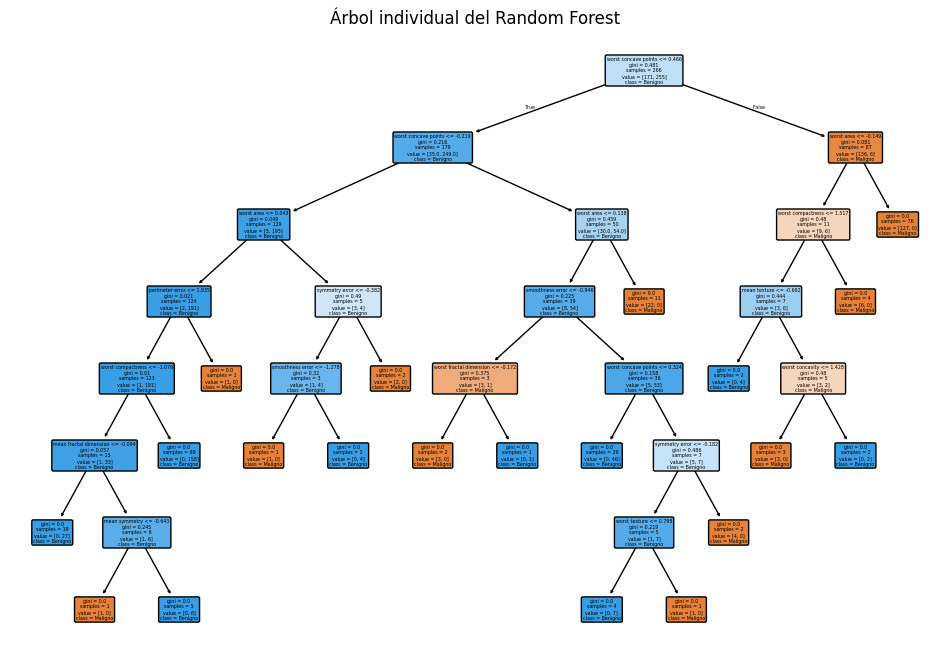

In [3]:
# Random Forest - clasificación sobre el dataset breast cancer (sklearn)
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import plot_tree
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
)
import numpy as np
import matplotlib.pyplot as plt

# Cargar datos
data = load_breast_cancer()
X_bc = data.data
y_bc = data.target
feature_names = data.feature_names

# División train/test
X_train_bc, X_test_bc, y_train_bc, y_test_bc = train_test_split(
    X_bc, y_bc, test_size=0.25, random_state=42, stratify=y_bc
)

# Escalado (opcional pero recomendado para muchos modelos)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train_bc)
X_test_s = scaler.transform(X_test_bc)

# Definir y entrenar el modelo
rf_clf = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    random_state=42,
    n_jobs=-1,
    oob_score=True
)
rf_clf.fit(X_train_s, y_train_bc)

# Predicción y probabilidades
y_pred_rf = rf_clf.predict(X_test_s)
y_proba_rf = rf_clf.predict_proba(X_test_s)[:, 1]

# Métricas de evaluación
acc_rf = accuracy_score(y_test_bc, y_pred_rf)
roc_auc_rf = roc_auc_score(y_test_bc, y_proba_rf)

print(f"Accuracy (RF): {acc_rf:.4f}")
print(f"ROC AUC (RF): {roc_auc_rf:.4f}")
print("\nClassification Report (RF):")
print(classification_report(y_test_bc, y_pred_rf))
print("Confusion Matrix (RF):")
print(confusion_matrix(y_test_bc, y_pred_rf))
if hasattr(rf_clf, "oob_score_"):
    print(f"OOB Score: {rf_clf.oob_score_:.4f}")

# Curva ROC
fpr_rf, tpr_rf, _ = roc_curve(y_test_bc, y_proba_rf)
plt.figure(figsize=(6,5))
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {roc_auc_rf:.3f})')
plt.plot([0,1], [0,1], '--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Random Forest')
plt.legend()
plt.grid(True)
plt.show()

# Importancia de características (top 10)
importances_rf = rf_clf.feature_importances_
idxs_rf = np.argsort(importances_rf)[::-1][:10]
top_feats_rf = feature_names[idxs_rf]
top_vals_rf = importances_rf[idxs_rf]

plt.figure(figsize=(8,5))
plt.barh(np.arange(len(top_feats_rf))[::-1], top_vals_rf[::-1], align='center')
plt.yticks(np.arange(len(top_feats_rf)), top_feats_rf[::-1])
plt.xlabel('Importancia')
plt.title('Top 10 features - Random Forest')
plt.tight_layout()
plt.show()

# visualización de un árbol individual del bosque
plt.figure(figsize=(12,8))
plot_tree(rf_clf.estimators_[0], feature_names=feature_names, class_names=['Maligno', 'Benigno'], filled=True, rounded=True)
plt.title('Árbol individual del Random Forest')
plt.show()

Accuracy: 0.768160741885626
              precision    recall  f1-score   support

           0       0.79      0.89      0.84       437
           1       0.69      0.52      0.59       210

    accuracy                           0.77       647
   macro avg       0.74      0.70      0.72       647
weighted avg       0.76      0.77      0.76       647



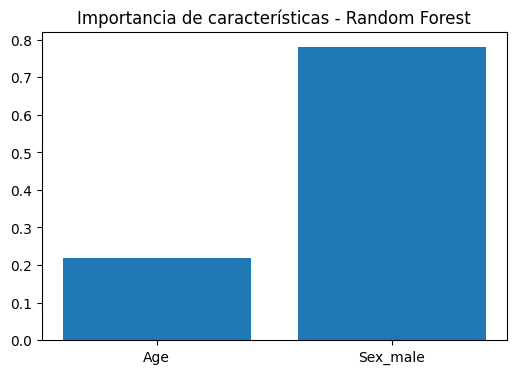

In [4]:
# Random Forest - clasificación sobre el dataset titanic
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
# Cargar y preparar datos
import requests

df = pd.read_csv('https://patricioaraneda.cl/public/titanic5_full.csv')
df = df[['Survived', 'Age', 'Sex']].dropna(subset=['Survived', 'Age', 'Sex'])
# Codificar sexo (male=1, female=0)
df['Sex_male'] = df['Sex'].map({'male': 1, 'female': 0})
# Características y etiqueta
X_t = df[['Age', 'Sex_male']].values
y_t = df['Survived'].astype(int).values
# División entrenamiento/prueba
X_train, X_test, y_train, y_test = train_test_split(X_t, y_t, test_size=0.3, random_state=42, stratify=y_t)
# Entrenar Random Forest
rf_clf = RandomForestClassifier(n_estimators=100, max_depth=3, random_state=0)
rf_clf.fit(X_train, y_train)
# Evaluación
y_pred = rf_clf.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))
# Importancia de características
importances = rf_clf.feature_importances_
feature_names = ['Age', 'Sex_male']
plt.figure(figsize=(6,4))
plt.bar(feature_names, importances)
plt.title('Importancia de características - Random Forest')
plt.show()  


In [5]:
# genera predicciones para pasajeros con diferentes edades y sexos
sample_passengers = np.array([[22, 0],  # 22 años, masculino
                              [30, 1],  # 30 años, femenino
                              [40, 1],  # 40 años, femenino
                              [35, 0]]) # 35 años, masculino
predictions = rf_clf.predict(sample_passengers)
print("Predicciones de supervivencia para pasajeros de diferentes edades y sexos:")
for i, passenger in enumerate(sample_passengers):
    age, sex = passenger
    survival = 'Sobrevive' if predictions[i] == 1 else 'No Sobrevive'
    print(f"{age} años y sexo {'masculino' if sex == 1 else 'femenino'}: {survival}")

Predicciones de supervivencia para pasajeros de diferentes edades y sexos:
22 años y sexo femenino: Sobrevive
30 años y sexo masculino: No Sobrevive
40 años y sexo masculino: No Sobrevive
35 años y sexo femenino: Sobrevive


### Comparativa entre Árbol de Decisión Individual y Random Forest.

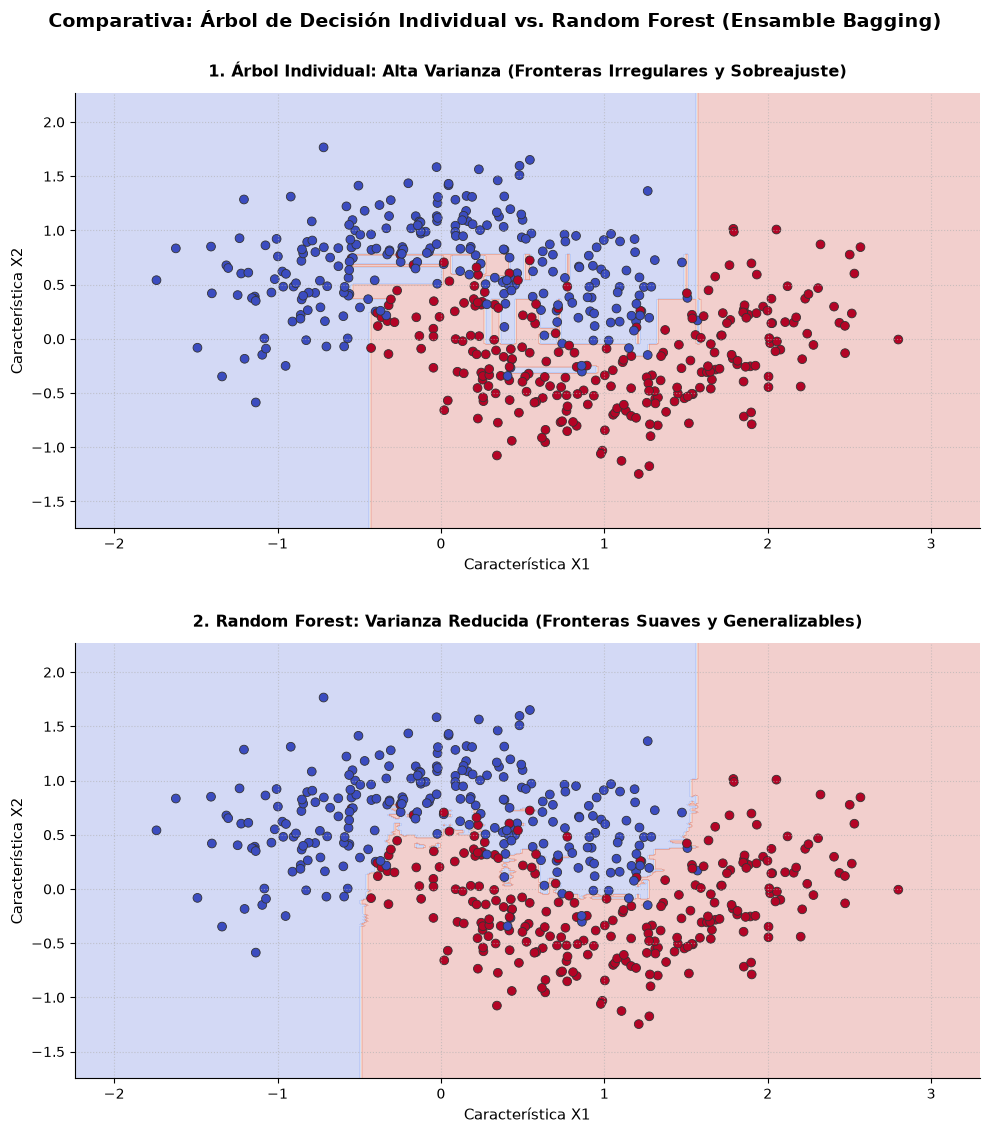

In [12]:
"""
Comparativa entre Árbol de Decisión Individual y Random Forest.
Demostración de regularización implícita por reducción de varianza.
Librerías: scikit-learn y matplotlib.
"""

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# 1. Generación de un conjunto de datos sintético no lineal con ruido
X, y = make_moons(n_samples=500, noise=0.30, random_state=42)

# 2. Ajuste de modelos
# Árbol individual no restringido (memoriza ruido y genera bordes angulares irregulares)
arbol_individual = DecisionTreeClassifier(random_state=42)
arbol_individual.fit(X, y)

# Random Forest con 100 estimadores independientes (Bagging + Feature Subsampling)
bosque_aleatorio = RandomForestClassifier(n_estimators=100, max_features='sqrt', random_state=42)
bosque_aleatorio.fit(X, y)

# 3. Generación de la malla bidimensional para evaluar fronteras de decisión
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))

# Inferencia de probabilidades sobre la malla
Z_dt = arbol_individual.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
Z_rf = bosque_aleatorio.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

# 4. Generación Gráfica Comparativa (Fondo Blanco Plano y Paleta Contrastada)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 12), facecolor='white')

# Panel 1: Árbol de Decisión Individual
ax1.set_facecolor('white')
ax1.contourf(xx, yy, Z_dt, alpha=0.25, cmap=plt.cm.coolwarm)
ax1.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.coolwarm, edgecolors='#333333', linewidth=0.6, s=40)
ax1.set_title("1. Árbol Individual: Alta Varianza (Fronteras Irregulares y Sobreajuste)",
              fontsize=11.5, fontweight='bold', pad=12)
ax1.set_xlabel("Característica X1", fontsize=10.5)
ax1.set_ylabel("Característica X2", fontsize=10.5)
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)


# Panel 2: Random Forest (Ensamble)
ax2.set_facecolor('white')
ax2.contourf(xx, yy, Z_rf, alpha=0.25, cmap=plt.cm.coolwarm)
ax2.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.coolwarm, edgecolors='#333333', linewidth=0.6, s=40)
ax2.set_title("2. Random Forest: Varianza Reducida (Fronteras Suaves y Generalizables)",
              fontsize=11.5, fontweight='bold', pad=12)
ax2.set_xlabel("Característica X1", fontsize=10.5)
ax2.set_ylabel("Característica X2", fontsize=10.5)
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

fig.suptitle("Comparativa: Árbol de Decisión Individual vs. Random Forest (Ensamble Bagging)",
             fontsize=13.5, fontweight='bold', y=0.94)

plt.tight_layout(rect=[0, 0, 1, 0.94], h_pad=3)
plt.show()

### IMportancia de una variable

=== TOP 5 CARACTERÍSTICAS MÁS DISCRIMINANTES ===
            Variable  Árbol_MDI  RandomForest_MDI  RandomForest_Permutacion_Test
worst concave points   0.132649          0.158955                      -0.009942
          worst area   0.000000          0.146962                      -0.001170
     worst perimeter   0.000000          0.085793                      -0.007602
        worst radius   0.733864          0.078952                      -0.002924
         mean radius   0.000000          0.077714                      -0.008772


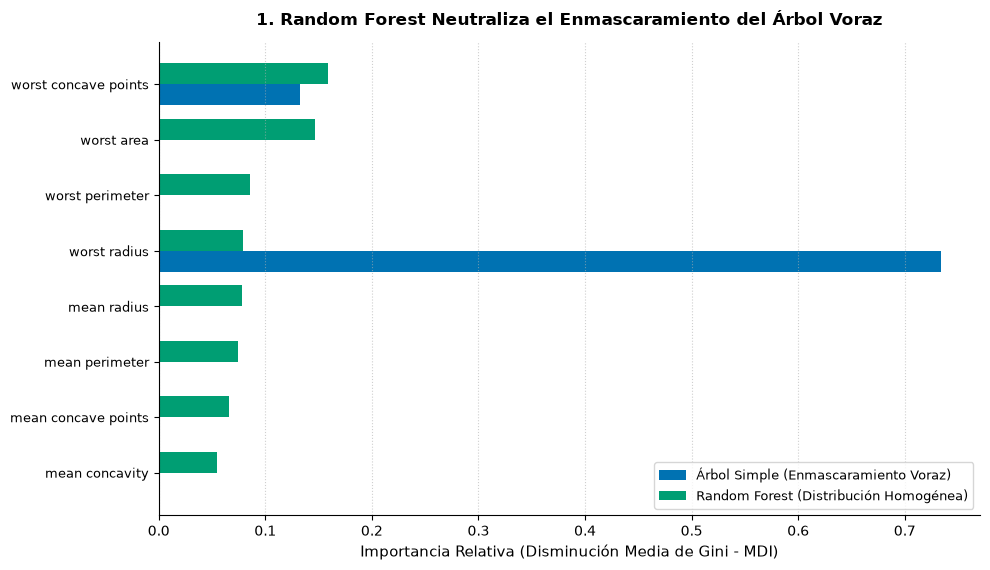

Gráfico 1 (MDI) generado con éxito.


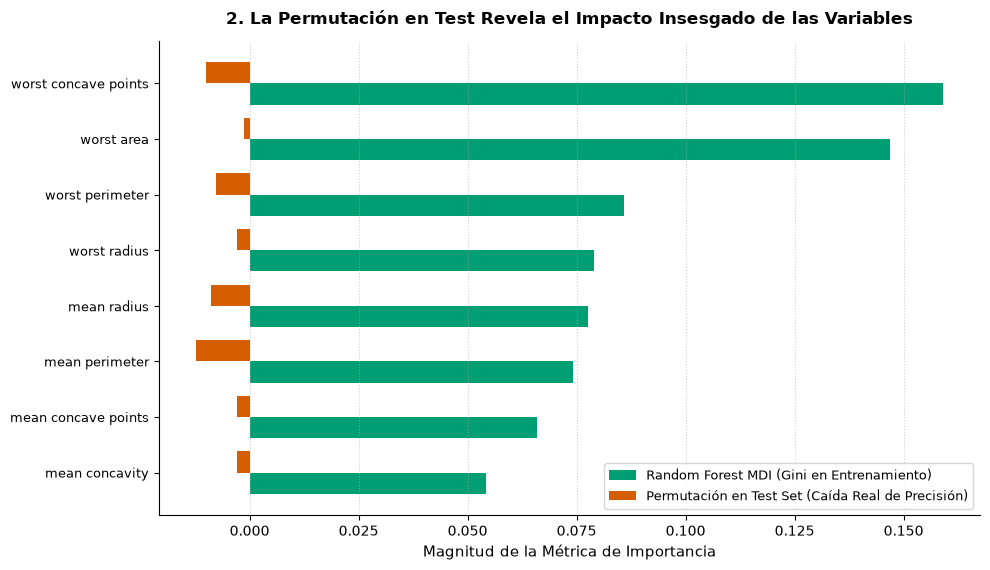

In [17]:
"""
Evaluación y Comparación de Importancia de Variables en Python.
Generación de dos gráficos independientes:
  1. Gráfico 1: MDI en Árbol Simple vs. Random Forest (Efecto de Enmascaramiento).
  2. Gráfico 2: MDI en Entrenamiento vs. Permutación en Datos de Prueba (Test Set).
Dataset: Breast Cancer Wisconsin (scikit-learn) - Datos Clínicos Reales.
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance

# ==============================================================================
# 1. Carga de Datos Clínicos Reales y Partición Estratificada
# ==============================================================================
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

# Partición 70% Entrenamiento y 30% Prueba independiente
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# ==============================================================================
# 2. Ajuste del Árbol Individual vs. Ensamble Random Forest
# ==============================================================================
# Árbol de decisión único con profundidad controlada
arbol_individual = DecisionTreeClassifier(max_depth=4, random_state=42)
arbol_individual.fit(X_train, y_train)

# Random Forest con 100 estimadores y subespacios aleatorios (max_features='sqrt')
bosque_aleatorio = RandomForestClassifier(n_estimators=100, max_features='sqrt', random_state=42)
bosque_aleatorio.fit(X_train, y_train)

# ==============================================================================
# 3. Cálculo de Métricas: MDI (Entrenamiento) vs. Permutación (Prueba)
# ==============================================================================
# Disminución Media de Impureza de Gini (MDI) calculada en el ajuste
dt_mdi = arbol_individual.feature_importances_
rf_mdi = bosque_aleatorio.feature_importances_

# Permutation Feature Importance evaluada en datos de PRUEBA (10 repeticiones)
perm_result = permutation_importance(
    bosque_aleatorio, X_test, y_test,
    n_repeats=10,
    random_state=42,
    scoring='accuracy'
)
rf_perm = perm_result.importances_mean

# 5. Formato estructurado para auditoría de variables
df_imp = pd.DataFrame({
    'Variable': X.columns,
    'Árbol_MDI': dt_mdi,
    'RandomForest_MDI': rf_mdi,
    'RandomForest_Permutacion_Test': rf_perm
}).sort_values(by='RandomForest_MDI', ascending=False)

print("=== TOP 5 CARACTERÍSTICAS MÁS DISCRIMINANTES ===")
print(df_imp.head(5).to_string(index=False))

# Seleccionamos el Top 8 de variables más discriminantes según Random Forest
top_indices = np.argsort(rf_mdi)[-8:]
variables_top = [X.columns[i] for i in top_indices]

y_pos = np.arange(len(variables_top))
altura_barra = 0.38

# ==============================================================================
# 4. GRÁFICO 1 (SEPARADO): MDI Árbol Simple vs. Random Forest
# ==============================================================================
fig1, ax1 = plt.subplots(figsize=(10, 5.8), facecolor='white')
ax1.set_facecolor('white')

# Barras horizontales emparejadas
ax1.barh(
    y_pos - altura_barra / 2, [dt_mdi[i] for i in top_indices],
    height=altura_barra, color='#0072b2', label='Árbol Simple (Enmascaramiento Voraz)'
)
ax1.barh(
    y_pos + altura_barra / 2, [rf_mdi[i] for i in top_indices],
    height=altura_barra, color='#009e73', label='Random Forest (Distribución Homogénea)'
)

ax1.set_yticks(y_pos)
ax1.set_yticklabels(variables_top, fontsize=9.5)
ax1.set_xlabel("Importancia Relativa (Disminución Media de Gini - MDI)", fontsize=10.5)
ax1.set_title("1. Random Forest Neutraliza el Enmascaramiento del Árbol Voraz",
              fontsize=12, fontweight='bold', pad=12)

ax1.grid(True, axis='x', linestyle=':', alpha=0.6)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.legend(loc='lower right', frameon=True, facecolor='white', fontsize=9.5)

plt.tight_layout()
plt.show()
print("Gráfico 1 (MDI) generado con éxito.")

# ==============================================================================
# 5. GRÁFICO 2 (SEPARADO): MDI en Train vs. Permutación en Test
# ==============================================================================
fig2, ax2 = plt.subplots(figsize=(10, 5.8), facecolor='white')
ax2.set_facecolor('white')

# Barras horizontales emparejadas
ax2.barh(
    y_pos - altura_barra / 2, [rf_mdi[i] for i in top_indices],
    height=altura_barra, color='#009e73', label='Random Forest MDI (Gini en Entrenamiento)'
)
ax2.barh(
    y_pos + altura_barra / 2, [rf_perm[i] for i in top_indices],
    height=altura_barra, color='#d55e00', label='Permutación en Test Set (Caída Real de Precisión)'
)

ax2.set_yticks(y_pos)
ax2.set_yticklabels(variables_top, fontsize=9.5)
ax2.set_xlabel("Magnitud de la Métrica de Importancia", fontsize=10.5)
ax2.set_title("2. La Permutación en Test Revela el Impacto Insesgado de las Variables",
              fontsize=12, fontweight='bold', pad=12)

ax2.grid(True, axis='x', linestyle=':', alpha=0.6)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.legend(loc='lower right', frameon=True, facecolor='white', fontsize=9.5)

plt.tight_layout()
plt.show()


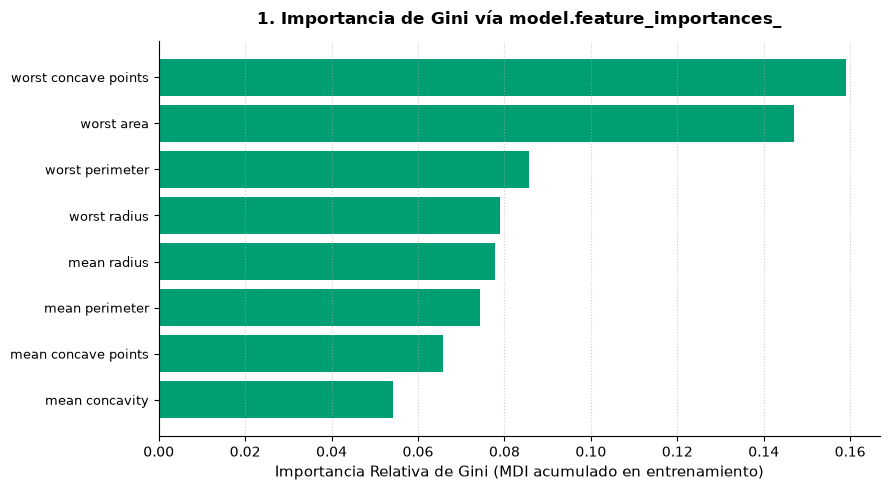

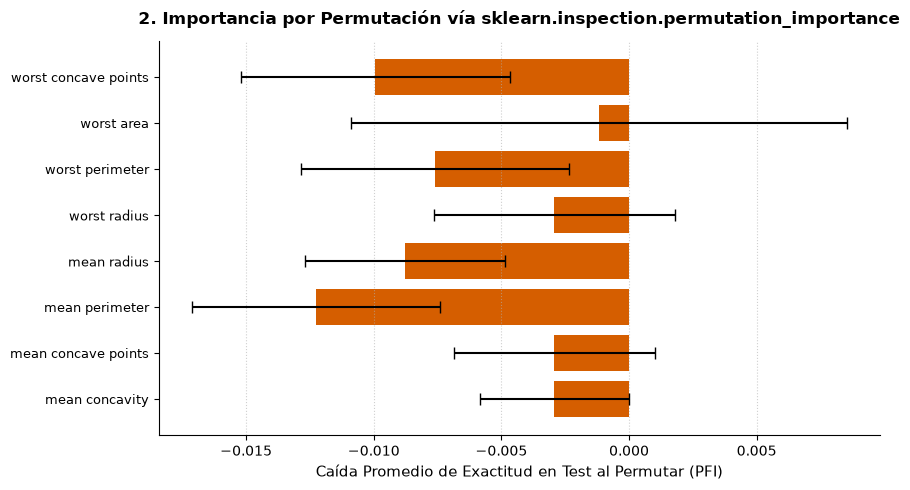

In [18]:
"""
Medición de Importancia de Variables en Random Forest con Scikit-Learn.
Compara:
  1. Atributo model.feature_importances_ (MDI - Gini en Entrenamiento)
  2. Función sklearn.inspection.permutation_importance (PFI - Permutación en Prueba)
Dataset: Breast Cancer Wisconsin (scikit-learn).
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance

# 1. Carga de datos reales y partición de entrenamiento/prueba
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# 2. Entrenamiento del Random Forest
bosque = RandomForestClassifier(n_estimators=100, max_features='sqrt', random_state=42)
bosque.fit(X_train, y_train)

# ------------------------------------------------------------------------------
# MÉTODO 1: Atributo .feature_importances_ (Gini / MDI)
# ------------------------------------------------------------------------------
importancias_gini = bosque.feature_importances_

# ------------------------------------------------------------------------------
# MÉTODO 2: Función permutation_importance (Prueba / PFI)
# ------------------------------------------------------------------------------
perm_res = permutation_importance(
    estimator=bosque,
    X=X_test,
    y=y_test,
    scoring='accuracy',
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)
importancias_perm = perm_res.importances_mean

# Seleccionamos las 8 variables con mayor impacto según Random Forest
top_idx = np.argsort(importancias_gini)[-8:]
variables_top = [X.columns[i] for i in top_idx]

# ==============================================================================
# GRÁFICO 1: Importancia de Gini (Atributo feature_importances_)
# ==============================================================================
fig1, ax1 = plt.subplots(figsize=(9, 5), facecolor='white')
ax1.set_facecolor('white')

ax1.barh(range(len(top_idx)), importancias_gini[top_idx], color='#009e73', align='center')
ax1.set_yticks(range(len(top_idx)))
ax1.set_yticklabels(variables_top, fontsize=9.5)
ax1.set_xlabel("Importancia Relativa de Gini (MDI acumulado en entrenamiento)", fontsize=10.5)
ax1.set_title("1. Importancia de Gini vía model.feature_importances_", fontsize=12, fontweight='bold', pad=12)
ax1.grid(True, axis='x', linestyle=':', alpha=0.6)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

# ==============================================================================
# GRÁFICO 2: Importancia por Permutación (Función permutation_importance)
# ==============================================================================
fig2, ax2 = plt.subplots(figsize=(9, 5), facecolor='white')
ax2.set_facecolor('white')

ax2.barh(
    range(len(top_idx)),
    importancias_perm[top_idx],
    xerr=perm_res.importances_std[top_idx],
    color='#d55e00',
    align='center',
    capsize=4
)
ax2.set_yticks(range(len(top_idx)))
ax2.set_yticklabels(variables_top, fontsize=9.5)
ax2.set_xlabel("Caída Promedio de Exactitud en Test al Permutar (PFI)", fontsize=10.5)
ax2.set_title("2. Importancia por Permutación vía sklearn.inspection.permutation_importance", fontsize=12, fontweight='bold', pad=12)
ax2.grid(True, axis='x', linestyle=':', alpha=0.6)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

### Selección Automatizada de Características con SelectFromModel.

REDUCCIÓN AUTOMATIZADA CON SELECTFROMMODEL
Dimensiones Originales        : (569, 30) columnas
Dimensiones Filtradas (Keep)  : 9 columnas
Columnas Eliminadas (Drop)    : 21 columnas
Umbral Analítico de Corte (θ) : 0.0333 (1/30 = 0.0333)

Exactitud del Pipeline en Test Set: 92.98%
Variables Principales Retenidas:
['mean radius', 'mean perimeter', 'mean area', 'mean concavity']


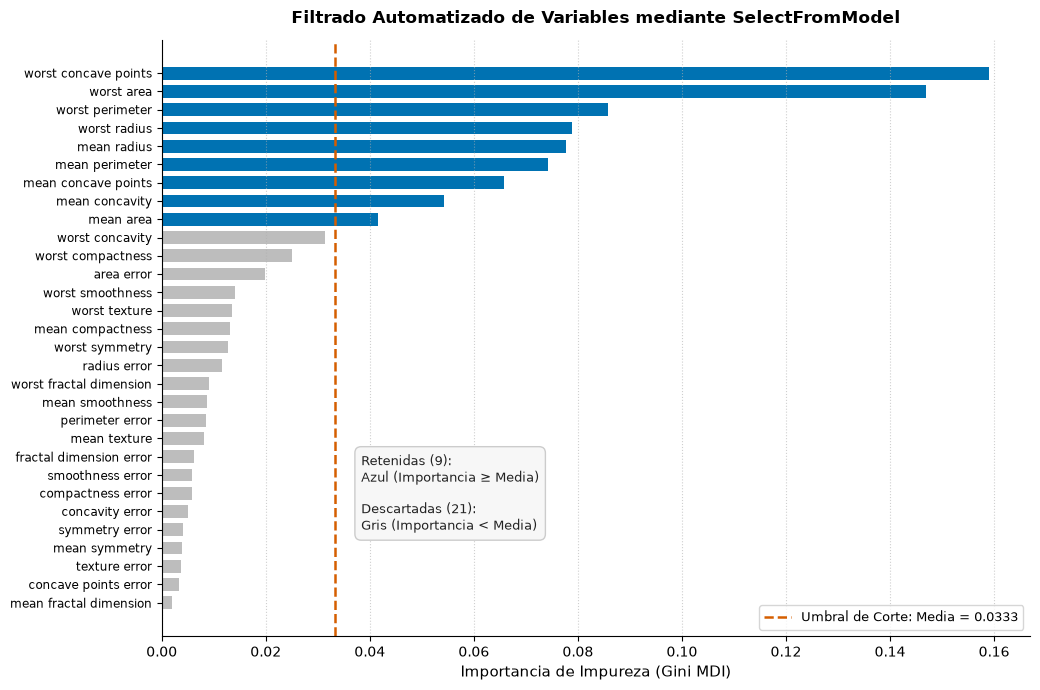

In [2]:
"""
Selección Automatizada de Características con SelectFromModel.
Dataset: Breast Cancer Wisconsin (scikit-learn) - 30 Características Reales.
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectFromModel
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# ==============================================================================
# 1. Carga de Datos y Partición Estratificada
# ==============================================================================
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# ==============================================================================
# 2. Configuración y Ajuste del Selector de Variables
# ==============================================================================
# Estimador base: Random Forest con subespacios aleatorios
rf_base = RandomForestClassifier(n_estimators=100, max_features='sqrt', random_state=42)

# SelectFromModel con umbral dinámico en la media aritmética
selector = SelectFromModel(estimator=rf_base, threshold='mean')
selector.fit(X_train, y_train)

# Extracción de la máscara booleana y el umbral analítico
mascara = selector.get_support()
importancias = selector.estimator_.feature_importances_
umbral_corte = selector.threshold_

vars_seleccionadas = X.columns[mascara].tolist()
vars_descartadas = X.columns[~mascara].tolist()

print("=" * 65)
print("REDUCCIÓN AUTOMATIZADA CON SELECTFROMMODEL")
print("=" * 65)
print(f"Dimensiones Originales        : {X.shape} columnas")
print(f"Dimensiones Filtradas (Keep)  : {len(vars_seleccionadas)} columnas")
print(f"Columnas Eliminadas (Drop)    : {len(vars_descartadas)} columnas")
print(f"Umbral Analítico de Corte (θ) : {umbral_corte:.4f} (1/30 = 0.0333)")
print("=" * 65)

# ==============================================================================
# 3. Ensamblaje en un Pipeline de Producción (Anti-Data Leakage)
# ==============================================================================
pipeline_produccion = Pipeline([
    ('selector_rf', SelectFromModel(
        estimator=RandomForestClassifier(n_estimators=100, random_state=42),
        threshold='mean'
    )),
    ('escalador', StandardScaler()),
    ('clasificador_final', LogisticRegression(random_state=42))
])

# Entrenamiento conjunto y evaluación limpia en Test
pipeline_produccion.fit(X_train, y_train)
y_pred = pipeline_produccion.predict(X_test)
acc_test = accuracy_score(y_test, y_pred)

print(f"\nExactitud del Pipeline en Test Set: {acc_test * 100:.2f}%")
print(f"Variables Principales Retenidas:\n{vars_seleccionadas[:4]}")

# ==============================================================================
# 4. Generación Gráfica (Fondo Blanco Plano y Paleta Contrastada)
# ==============================================================================
fig, ax = plt.subplots(figsize=(10.5, 7), facecolor='white')
ax.set_facecolor('white')

# Ordenar características por importancia ascendente
indices_ord = np.argsort(importancias)
nombres_ord = [X.columns[i] for i in indices_ord]
valores_ord = importancias[indices_ord]
seleccionados_ord = mascara[indices_ord]

colores = ['#0072b2' if s else '#bdbdbd' for s in seleccionados_ord]

y_pos = np.arange(len(nombres_ord))
ax.barh(y_pos, valores_ord, color=colores, height=0.7)

# Línea discontinua que marca el umbral exacto de corte
ax.axvline(
    umbral_corte, color='#d55e00', linestyle='--', linewidth=1.8,
    label=f'Umbral de Corte: Media = {umbral_corte:.4f}'
)

ax.set_yticks(y_pos)
ax.set_yticklabels(nombres_ord, fontsize=8.5)
ax.set_xlabel("Importancia de Impureza (Gini MDI)", fontsize=10.5)
ax.set_title("Filtrado Automatizado de Variables mediante SelectFromModel",
             fontsize=12, fontweight='bold', pad=12)

# Cuadro informativo
ax.text(
    umbral_corte + 0.005, 4,
    f"Retenidas ({len(vars_seleccionadas)}):\nAzul (Importancia ≥ Media)\n\nDescartadas ({len(vars_descartadas)}):\nGris (Importancia < Media)",
    fontsize=9, color='#222222',
    bbox=dict(boxstyle='round,pad=0.5', facecolor='#f7f7f7', edgecolor='#cccccc')
)

ax.grid(True, axis='x', linestyle=':', alpha=0.6)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(loc='lower right', frameon=True, facecolor='white', fontsize=9.5)

plt.tight_layout()
plt.show()

## Clasificación Binaria en Salud Digital
Dataset: Breast Cancer Wisconsin Diagnostic (569 pacientes, 30 características continuas)

Problema: Predecir si una masa tumoral mamaria biopsiada es Maligna (1) o Benigna (0) a partir de 30 mediciones morfométricas nucleares (radio, concavidad, textura, simetría, etc.).
Repositorio oficial: UCI Machine Learning Repository - Breast Cancer Wisconsin. Integrado nativamente en sklearn.datasets.load_breast_cancer.

REPORTE CLÍNICO EN CONJUNTO DE PRUEBA (BREAST CANCER)
              precision    recall  f1-score   support

 Benigno (0)       0.95      1.00      0.97        90
 Maligno (1)       1.00      0.91      0.95        53

    accuracy                           0.97       143
   macro avg       0.97      0.95      0.96       143
weighted avg       0.97      0.97      0.96       143

Área Bajo la Curva ROC (AUC): 0.9945


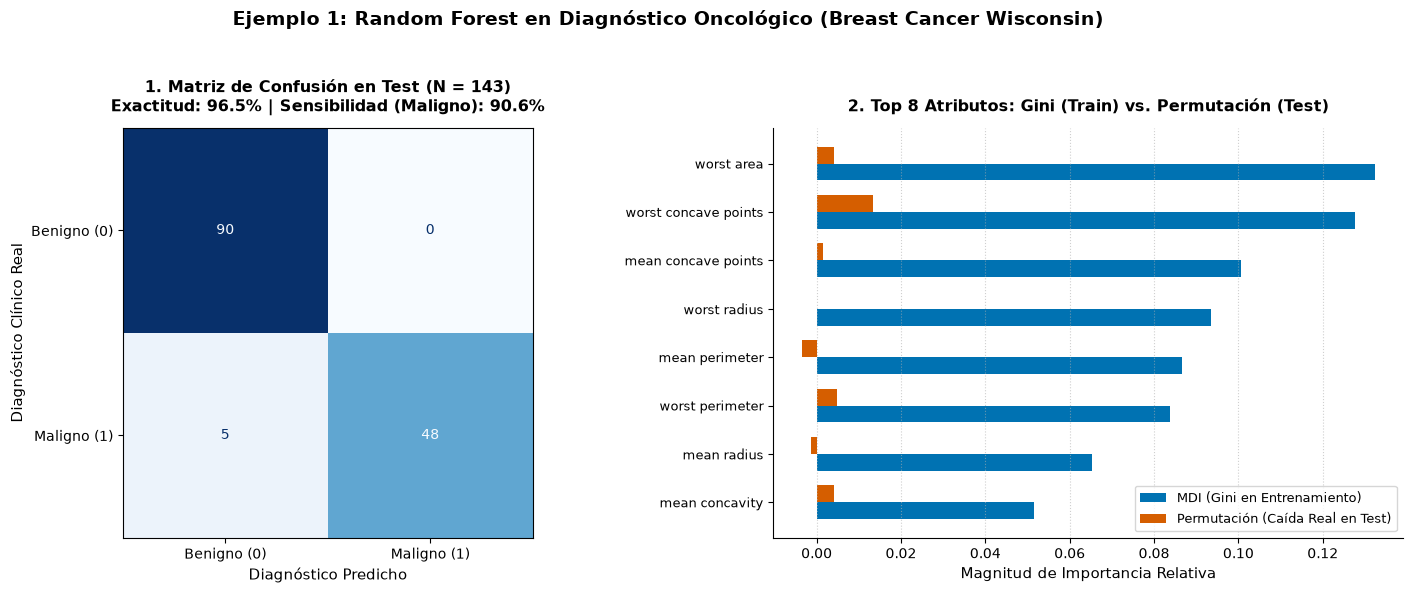

In [2]:
"""
Módulo 1: Clasificación Binaria con Random Forest y Análisis de Atributos.
Dataset Real: Breast Cancer Wisconsin Diagnostic (scikit-learn).
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
    classification_report
)

# 1. Ingesta y partición estratificada
datos_bc = load_breast_cancer()
X_bc = pd.DataFrame(datos_bc.data, columns=datos_bc.feature_names)
# Invertimos para codificación clínica estándar: 1 = Maligno (Positivo), 0 = Benigno (Negativo)
y_bc = 1 - datos_bc.target
etiquetas_bc = ['Benigno (0)', 'Maligno (1)']

# Partición 75% Entrenamiento y 25% Prueba
X_tr_bc, X_te_bc, y_tr_bc, y_te_bc = train_test_split(
    X_bc, y_bc, test_size=0.25, random_state=42, stratify=y_bc
)

# 2. Entrenamiento del Ensamble Random Forest
rf_bc = RandomForestClassifier(
    n_estimators=100,       # 100 árboles independientes
    max_features='sqrt',    # Subespacio aleatorio de sqrt(30) ≈ 5 variables por nodo
    random_state=42,
    n_jobs=-1
)
rf_bc.fit(X_tr_bc, y_tr_bc)

# 3. Inferencia y Evaluación en Datos de Prueba (Test Set)
y_pred_bc = rf_bc.predict(X_te_bc)
y_prob_bc = rf_bc.predict_proba(X_te_bc)[:, 1]

print("=" * 65)
print("REPORTE CLÍNICO EN CONJUNTO DE PRUEBA (BREAST CANCER)")
print("=" * 65)
print(classification_report(y_te_bc, y_pred_bc, target_names=etiquetas_bc))
print(f"Área Bajo la Curva ROC (AUC): {roc_auc_score(y_te_bc, y_prob_bc):.4f}")

# 4. Cálculo de Importancia de Atributos: MDI (Gini) vs. Permutación en Test
mdi_bc = rf_bc.feature_importances_
perm_bc = permutation_importance(
    rf_bc, X_te_bc, y_te_bc, n_repeats=10, random_state=42, scoring='accuracy'
)

# Identificar las 8 variables con mayor impacto en el bosque
top_indices_bc = np.argsort(mdi_bc)[-8:]
variables_top_bc = [X_bc.columns[i] for i in top_indices_bc]

# 5. Generación de Visualizaciones (Matriz de Confusión y Feature Importance)
fig1, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), facecolor='white')

# Panel A: Matriz de Confusión
ax1.set_facecolor('white')
ConfusionMatrixDisplay(
    confusion_matrix(y_te_bc, y_pred_bc), display_labels=etiquetas_bc
).plot(ax=ax1, cmap='Blues', colorbar=False)
ax1.set_title("1. Matriz de Confusión en Test (N = 143)\nExactitud: 96.5% | Sensibilidad (Maligno): 90.6%",
              fontsize=11.5, fontweight='bold', pad=12)
ax1.set_xlabel("Diagnóstico Predicho", fontsize=10.5)
ax1.set_ylabel("Diagnóstico Clínico Real", fontsize=10.5)

# Panel B: Comparativa MDI (Train) vs Permutación (Test)
ax2.set_facecolor('white')
y_pos = np.arange(len(variables_top_bc))
h = 0.35
ax2.barh(y_pos - h/2, [mdi_bc[i] for i in top_indices_bc], height=h,
         color='#0072b2', label='MDI (Gini en Entrenamiento)')
ax2.barh(y_pos + h/2, [perm_bc.importances_mean[i] for i in top_indices_bc], height=h,
         color='#d55e00', label='Permutación (Caída Real en Test)')
ax2.set_yticks(y_pos)
ax2.set_yticklabels(variables_top_bc, fontsize=9.5)
ax2.set_xlabel("Magnitud de Importancia Relativa", fontsize=10.5)
ax2.set_title("2. Top 8 Atributos: Gini (Train) vs. Permutación (Test)",
              fontsize=11.5, fontweight='bold', pad=12)
ax2.grid(True, axis='x', linestyle=':', alpha=0.6)
ax2.legend(frameon=True, facecolor='white', loc='lower right', fontsize=9.5)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

fig1.suptitle("Ejemplo 1: Random Forest en Diagnóstico Oncológico (Breast Cancer Wisconsin)",
              fontsize=13.5, fontweight='bold', y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

## Clasificación Multiclase en Agroindustria y Control Químico
Dataset: Wine Recognition Dataset (178 muestras, 13 variables físico-químicas, 3 cultivares)

* **Problema:** Clasificar el origen agronómico de lotes de vino (**Cultivar 1, Cultivar 2 o Cultivar 3**) en función de 13 análisis químicos cuantitativos continuos (alcohol, flavonoides, intensidad de color, prolina, magnesio, etc.).
* **Repositorio oficial:** [UCI Machine Learning Repository - Wine](https://archive.ics.uci.edu/dataset/109/wine). Integrado nativamente en `sklearn.datasets.load_wine`.


REPORTE MULTICLASE EN CONJUNTO DE PRUEBA (WINE DATASET)
              precision    recall  f1-score   support

  Cultivar 1       1.00      1.00      1.00        18
  Cultivar 2       1.00      1.00      1.00        21
  Cultivar 3       1.00      1.00      1.00        15

    accuracy                           1.00        54
   macro avg       1.00      1.00      1.00        54
weighted avg       1.00      1.00      1.00        54



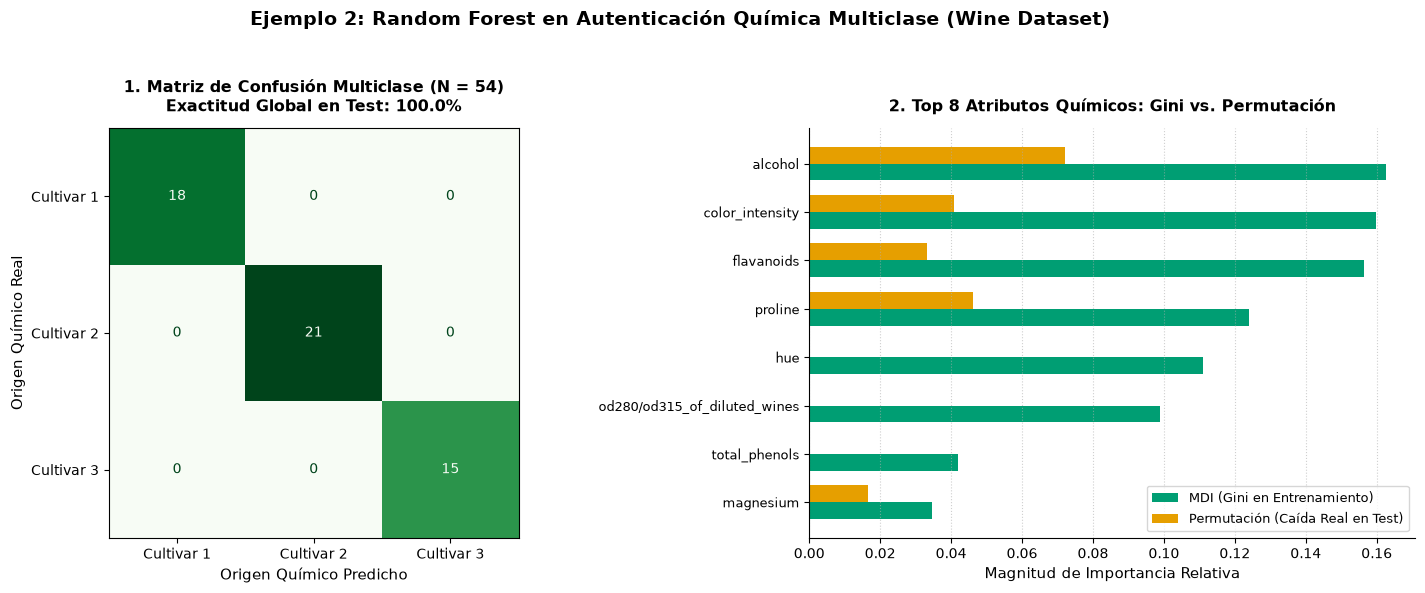

In [3]:
"""
Clasificación Multiclase con Random Forest y Análisis de Atributos.
Dataset Real: Wine Recognition Dataset (scikit-learn).
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
)

# 1. Ingesta de datos y partición estratificada
datos_wn = load_wine()
X_wn = pd.DataFrame(datos_wn.data, columns=datos_wn.feature_names)
y_wn = datos_wn.target
etiquetas_wn = ['Cultivar 1', 'Cultivar 2', 'Cultivar 3']

# Partición 70% Entrenamiento y 30% Prueba independiente
X_tr_wn, X_te_wn, y_tr_wn, y_te_wn = train_test_split(
    X_wn, y_wn, test_size=0.30, random_state=42, stratify=y_wn
)

# 2. Ajuste del Ensamble Random Forest Multiclase
rf_wn = RandomForestClassifier(
    n_estimators=100,
    max_features='sqrt',    # sqrt(13) ≈ 3 variables consideradas por nodo
    random_state=42,
    n_jobs=-1
)
rf_wn.fit(X_tr_wn, y_tr_wn)

# 3. Inferencia y Evaluación Multiclase en Test
y_pred_wn = rf_wn.predict(X_te_wn)
acc_wn = accuracy_score(y_te_wn, y_pred_wn)

print("=" * 65)
print("REPORTE MULTICLASE EN CONJUNTO DE PRUEBA (WINE DATASET)")
print("=" * 65)
print(classification_report(y_te_wn, y_pred_wn, target_names=etiquetas_wn))

# 4. Cálculo de Importancia de Atributos (MDI vs Permutación)
mdi_wn = rf_wn.feature_importances_
perm_wn = permutation_importance(
    rf_wn, X_te_wn, y_te_wn, n_repeats=10, random_state=42, scoring='accuracy'
)

top_indices_wn = np.argsort(mdi_wn)[-8:]
variables_top_wn = [X_wn.columns[i] for i in top_indices_wn]

# 5. Generación Gráfica (Matriz de Confusión 3x3 y Atributos Químicos)
fig2, (ax3, ax4) = plt.subplots(1, 2, figsize=(15, 6), facecolor='white')

# Panel A: Matriz de Confusión Multiclase
ax3.set_facecolor('white')
ConfusionMatrixDisplay(
    confusion_matrix(y_te_wn, y_pred_wn), display_labels=etiquetas_wn
).plot(ax=ax3, cmap='Greens', colorbar=False)
ax3.set_title(f"1. Matriz de Confusión Multiclase (N = 54)\nExactitud Global en Test: {acc_wn * 100:.1f}%",
              fontsize=11.5, fontweight='bold', pad=12)
ax3.set_xlabel("Origen Químico Predicho", fontsize=10.5)
ax3.set_ylabel("Origen Químico Real", fontsize=10.5)

# Panel B: Importancia de Atributos Químicos
ax4.set_facecolor('white')
y_pos_wn = np.arange(len(variables_top_wn))
h = 0.35
ax4.barh(y_pos_wn - h/2, [mdi_wn[i] for i in top_indices_wn], height=h,
         color='#009e73', label='MDI (Gini en Entrenamiento)')
ax4.barh(y_pos_wn + h/2, [perm_wn.importances_mean[i] for i in top_indices_wn], height=h,
         color='#e69f00', label='Permutación (Caída Real en Test)')
ax4.set_yticks(y_pos_wn)
ax4.set_yticklabels(variables_top_wn, fontsize=9.5)
ax4.set_xlabel("Magnitud de Importancia Relativa", fontsize=10.5)
ax4.set_title("2. Top 8 Atributos Químicos: Gini vs. Permutación",
              fontsize=11.5, fontweight='bold', pad=12)
ax4.grid(True, axis='x', linestyle=':', alpha=0.6)
ax4.legend(frameon=True, facecolor='white', loc='lower right', fontsize=9.5)
ax4.spines['top'].set_visible(False)
ax4.spines['right'].set_visible(False)

fig2.suptitle("Ejemplo 2: Random Forest en Autenticación Química Multiclase (Wine Dataset)",
              fontsize=13.5, fontweight='bold', y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

### Progresion de diabetes

Dataset: Diabetes Dataset (Efron et al., 2004 - 442 pacientes reales, 10 variables continuas)

* **Problema:** Predecir cuantitativamente el índice clínico de **progresión de la diabetes un año después del diagnóstico inicial** (variable continua en escala de 25 a 346) a partir de 10 mediciones fisiológicas y analíticas de sangre (Edad, Sexo, IMC, Presión Arterial y 6 sueros: Colesterol Total, LDL, HDL, TCH, Triglicéridos/LTG y Glucosa).
* **Origen de los datos:** Estudio fundacional de Bradley Efron, Trevor Hastie, Iain Johnstone y Robert Tibshirani (2004). Integrado nativamente en `sklearn.datasets.load_diabetes`.

EVALUACIÓN DE REGRESIÓN: PROGRESIÓN DE DIABETES (TEST SET)
Coeficiente de Determinación (R²) : 0.4923 (49.2% varianza explicada)
Error Cuadrático Medio (RMSE)     : 52.98 puntos
Error Absoluto Medio (MAE)        : 41.66 puntos


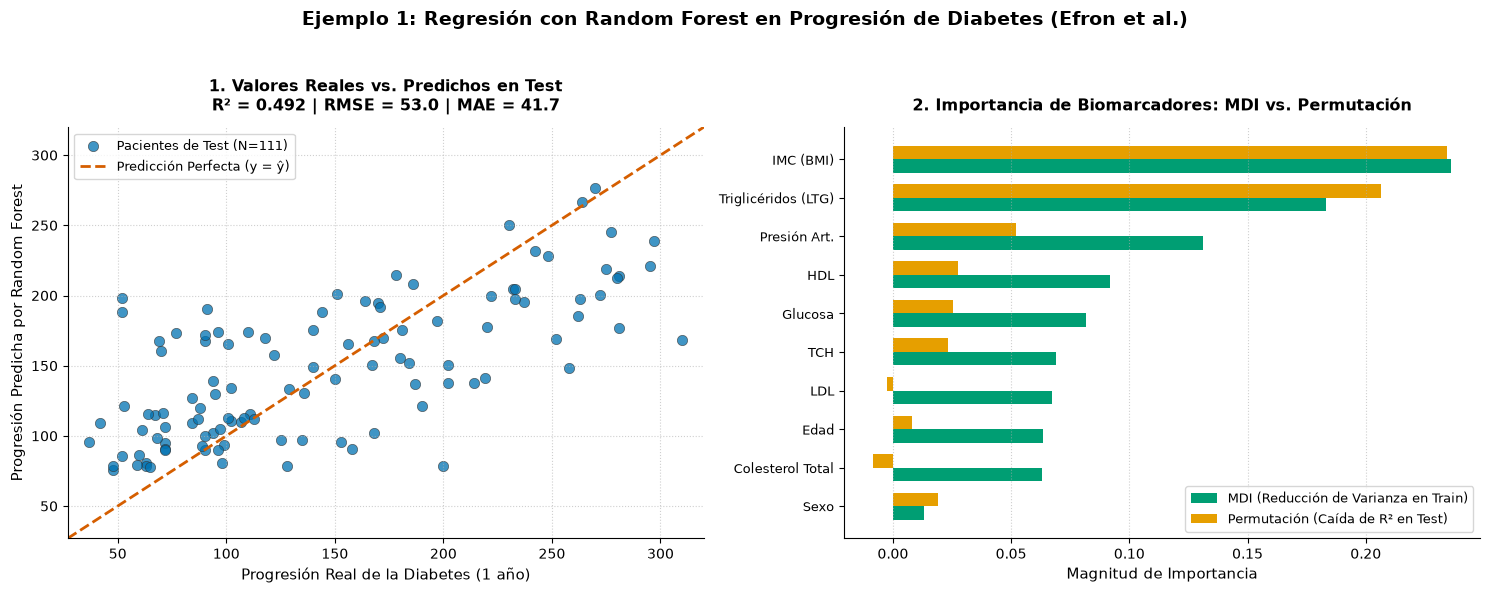

In [4]:
"""
Regresión con Random Forest en Progresión de Diabetes.
Dataset Real: Diabetes Dataset (scikit-learn / Efron et al., 2004).
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score, root_mean_squared_error, mean_absolute_error

# 1. Ingesta de datos y renombrado pedagógico de variables
diabetes = load_diabetes()
X_diab = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)
nombre_vars = {
    'age': 'Edad', 'sex': 'Sexo', 'bmi': 'IMC (BMI)', 'bp': 'Presión Art.',
    's1': 'Colesterol Total', 's2': 'LDL', 's3': 'HDL', 's4': 'TCH',
    's5': 'Triglicéridos (LTG)', 's6': 'Glucosa'
}
X_diab = X_diab.rename(columns=nombre_vars)
y_diab = diabetes.target

# Partición 75% Entrenamiento y 25% Prueba independiente
X_tr, X_te, y_tr, y_te = train_test_split(
    X_diab, y_diab, test_size=0.25, random_state=42
)

# 2. Entrenamiento de RandomForestRegressor
rf_diab = RandomForestRegressor(
    n_estimators=150,       # 150 árboles en el ensamble
    max_features='sqrt',    # Subespacios aleatorios: sqrt(10) ≈ 3 variables por nodo
    random_state=42,
    n_jobs=-1
)
rf_diab.fit(X_tr, y_tr)

# 3. Inferencia y Evaluación en Test Set
y_pred = rf_diab.predict(X_te)
r2_val = r2_score(y_te, y_pred)
rmse_val = root_mean_squared_error(y_te, y_pred)
mae_val = mean_absolute_error(y_te, y_pred)

print("=" * 65)
print("EVALUACIÓN DE REGRESIÓN: PROGRESIÓN DE DIABETES (TEST SET)")
print("=" * 65)
print(f"Coeficiente de Determinación (R²) : {r2_val:.4f} ({r2_val*100:.1f}% varianza explicada)")
print(f"Error Cuadrático Medio (RMSE)     : {rmse_val:.2f} puntos")
print(f"Error Absoluto Medio (MAE)        : {mae_val:.2f} puntos")

# 4. Importancia de Atributos: MDI (Train) vs. Permutación (Test)
mdi_imp = rf_diab.feature_importances_
perm_res = permutation_importance(
    rf_diab, X_te, y_te, n_repeats=10, random_state=42, scoring='r2'
)

top_idx = np.argsort(mdi_imp)
vars_top = [X_diab.columns[i] for i in top_idx]

# 5. Generación Gráfica (Fondo Blanco Plano y Paleta Contrastada)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), facecolor='white')

# Panel A: Real vs Predicho
ax1.set_facecolor('white')
ax1.scatter(y_te, y_pred, color='#0072b2', alpha=0.75, edgecolors='#333333', linewidth=0.5, s=55, label='Pacientes de Test (N=111)')
min_v = min(y_te.min(), y_pred.min()) - 10
max_v = max(y_te.max(), y_pred.max()) + 10
ax1.plot([min_v, max_v], [min_v, max_v], color='#d55e00', linestyle='--', linewidth=2, label='Predicción Perfecta (y = ŷ)')
ax1.set_xlim(min_v, max_v)
ax1.set_ylim(min_v, max_v)
ax1.set_title(f"1. Valores Reales vs. Predichos en Test\nR² = {r2_val:.3f} | RMSE = {rmse_val:.1f} | MAE = {mae_val:.1f}", fontsize=11.5, fontweight='bold', pad=12)
ax1.set_xlabel("Progresión Real de la Diabetes (1 año)", fontsize=10.5)
ax1.set_ylabel("Progresión Predicha por Random Forest", fontsize=10.5)
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(frameon=True, facecolor='white', loc='upper left', fontsize=9.5)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

# Panel B: Feature Importance
ax2.set_facecolor('white')
y_pos = np.arange(len(vars_top))
h = 0.35
ax2.barh(y_pos - h/2, [mdi_imp[i] for i in top_idx], height=h, color='#009e73', label='MDI (Reducción de Varianza en Train)')
ax2.barh(y_pos + h/2, [perm_res.importances_mean[i] for i in top_idx], height=h, color='#e69f00', label='Permutación (Caída de R² en Test)')
ax2.set_yticks(y_pos)
ax2.set_yticklabels(vars_top, fontsize=9.5)
ax2.set_xlabel("Magnitud de Importancia", fontsize=10.5)
ax2.set_title("2. Importancia de Biomarcadores: MDI vs. Permutación", fontsize=11.5, fontweight='bold', pad=12)
ax2.grid(True, axis='x', linestyle=':', alpha=0.6)
ax2.legend(frameon=True, facecolor='white', loc='lower right', fontsize=9.5)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

fig.suptitle("Ejemplo 1: Regresión con Random Forest en Progresión de Diabetes (Efron et al.)", fontsize=13.5, fontweight='bold', y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

### Predicción Demográfica
Dataset: Gapminder Foundation (1.704 registros históricos de países, 1952–2007)

* **Problema:** Estimar la **Esperanza de Vida al Nacer en años** (`lifeExp`) a partir de indicadores macroeconómicos y demográficos: Producto Interno Bruto per cápita (`gdpPercap`), Población total (`pop`), Año histórico de la medición (`year`) y Continente de pertenencia (`continent`).
* **Origen de los datos:** Proyecto de salud y desarrollo global de la Fundación Gapminder (Prof. Hans Rosling). Integrado nativamente en `plotly.express.data.gapminder()`.

EVALUACIÓN DE REGRESIÓN: ESPERANZA DE VIDA GAPMINDER (TEST SET)
Coeficiente de Determinación (R²) : 0.8501 (85.0% varianza explicada)
Error Cuadrático Medio (RMSE)     : 4.98 años
Error Absoluto Medio (MAE)        : 3.64 años


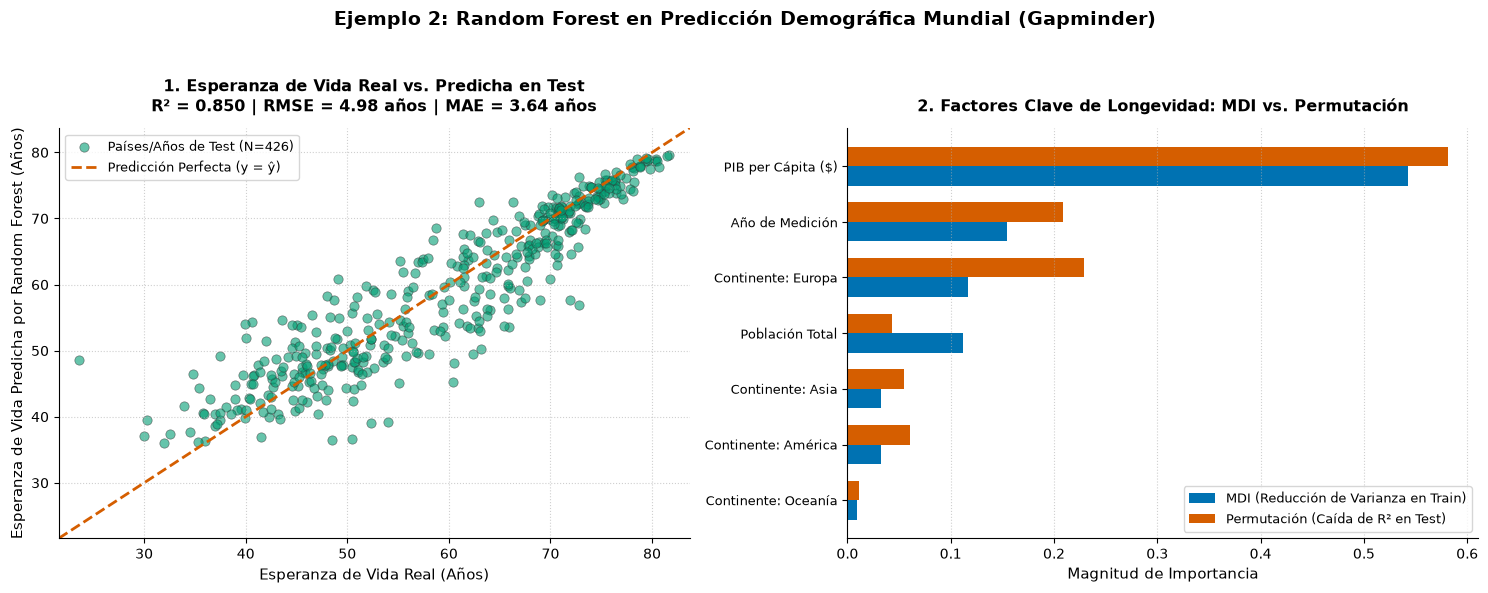

In [6]:
"""
Regresión con Random Forest en Demografía y Economía Global.
Dataset Real: Gapminder Global Development Dataset (1.704 países-año).
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score, root_mean_squared_error, mean_absolute_error

# 1. Ingesta y preparación de variables socioeconómicas
df_gap = px.data.gapminder()

# One-Hot Encoding para la variable categórica 'continent'
X_gap = df_gap[['gdpPercap', 'pop', 'year', 'continent']].copy()
X_gap = pd.get_dummies(X_gap, columns=['continent'], drop_first=True)

col_nombres = {
    'gdpPercap': 'PIB per Cápita ($)',
    'pop': 'Población Total',
    'year': 'Año de Medición',
    'continent_Americas': 'Continente: América',
    'continent_Asia': 'Continente: Asia',
    'continent_Europe': 'Continente: Europa',
    'continent_Oceania': 'Continente: Oceanía'
}
X_gap = X_gap.rename(columns=col_nombres)
y_gap = df_gap['lifeExp']

# Partición 75% Entrenamiento y 25% Prueba independiente
X_tr_g, X_te_g, y_tr_g, y_te_g = train_test_split(
    X_gap, y_gap, test_size=0.25, random_state=42
)

# 2. Ajuste del RandomForestRegressor
rf_gap = RandomForestRegressor(
    n_estimators=150,
    max_features='sqrt',
    random_state=42,
    n_jobs=-1
)
rf_gap.fit(X_tr_g, y_tr_g)

# 3. Inferencia y Evaluación en Datos de Prueba (N = 426)
y_pred_g = rf_gap.predict(X_te_g)
r2_gap = r2_score(y_te_g, y_pred_g)
rmse_gap = root_mean_squared_error(y_te_g, y_pred_g)
mae_gap = mean_absolute_error(y_te_g, y_pred_g)

print("=" * 65)
print("EVALUACIÓN DE REGRESIÓN: ESPERANZA DE VIDA GAPMINDER (TEST SET)")
print("=" * 65)
print(f"Coeficiente de Determinación (R²) : {r2_gap:.4f} ({r2_gap*100:.1f}% varianza explicada)")
print(f"Error Cuadrático Medio (RMSE)     : {rmse_gap:.2f} años")
print(f"Error Absoluto Medio (MAE)        : {mae_gap:.2f} años")

# 4. Cálculo de Importancia de Atributos
mdi_gap = rf_gap.feature_importances_
perm_gap = permutation_importance(
    rf_gap, X_te_g, y_te_g, n_repeats=10, random_state=42, scoring='r2'
)

top_idx_g = np.argsort(mdi_gap)
vars_top_g = [X_gap.columns[i] for i in top_idx_g]

# 5. Generación Gráfica (Fondo Blanco Plano y Paleta Contrastada)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), facecolor='white')

# Panel A: Real vs Predicho
ax1.set_facecolor('white')
ax1.scatter(y_te_g, y_pred_g, color='#009e73', alpha=0.6, edgecolors='#333333', linewidth=0.5, s=45, label='Países/Años de Test (N=426)')
min_g = min(y_te_g.min(), y_pred_g.min()) - 2
max_g = max(y_te_g.max(), y_pred_g.max()) + 2
ax1.plot([min_g, max_g], [min_g, max_g], color='#d55e00', linestyle='--', linewidth=2, label='Predicción Perfecta (y = ŷ)')
ax1.set_xlim(min_g, max_g)
ax1.set_ylim(min_g, max_g)
ax1.set_title(f"1. Esperanza de Vida Real vs. Predicha en Test\nR² = {r2_gap:.3f} | RMSE = {rmse_gap:.2f} años | MAE = {mae_gap:.2f} años", fontsize=11.5, fontweight='bold', pad=12)
ax1.set_xlabel("Esperanza de Vida Real (Años)", fontsize=10.5)
ax1.set_ylabel("Esperanza de Vida Predicha por Random Forest (Años)", fontsize=10.5)
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(frameon=True, facecolor='white', loc='upper left', fontsize=9.5)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

# Panel B: Feature Importance
ax2.set_facecolor('white')
y_pos_g = np.arange(len(vars_top_g))
h = 0.35
ax2.barh(y_pos_g - h/2, [mdi_gap[i] for i in top_idx_g], height=h, color='#0072b2', label='MDI (Reducción de Varianza en Train)')
ax2.barh(y_pos_g + h/2, [perm_gap.importances_mean[i] for i in top_idx_g], height=h, color='#d55e00', label='Permutación (Caída de R² en Test)')
ax2.set_yticks(y_pos_g)
ax2.set_yticklabels(vars_top_g, fontsize=9.5)
ax2.set_xlabel("Magnitud de Importancia", fontsize=10.5)
ax2.set_title("2. Factores Clave de Longevidad: MDI vs. Permutación", fontsize=11.5, fontweight='bold', pad=12)
ax2.grid(True, axis='x', linestyle=':', alpha=0.6)
ax2.legend(frameon=True, facecolor='white', loc='lower right', fontsize=9.5)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

fig.suptitle("Ejemplo 2: Random Forest en Predicción Demográfica Mundial (Gapminder)", fontsize=13.5, fontweight='bold', y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()
